<a href="https://colab.research.google.com/github/Gchirico63/Didattica/blob/main/statistics/Poisson_versus_Gaussian.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

(30,) (31,) (30,)


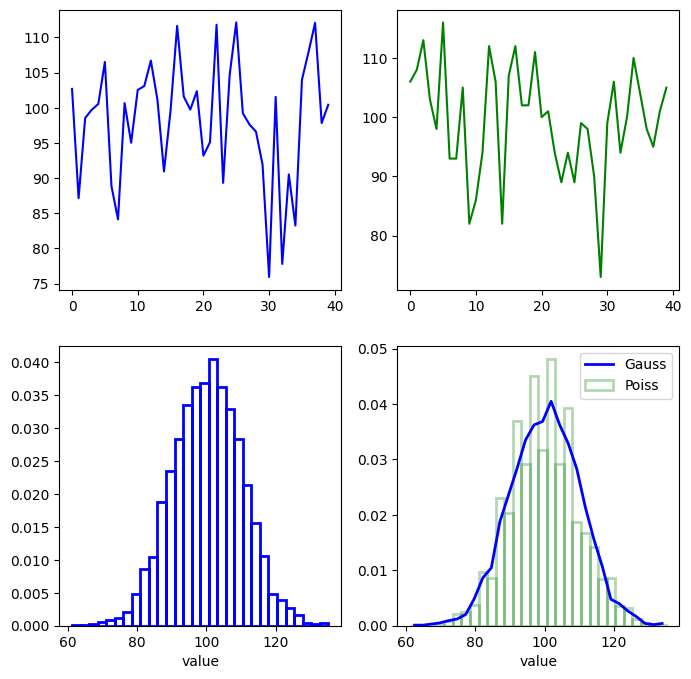

In [6]:
'''
Poisson and Gaussian distriobutions
'''

import numpy as np
import matplotlib.pyplot as plt

def centri(bb):
  bins_center = np.zeros(bb.shape[0]-1)

  for k in range(bb.size-1):
    bins_center[k] = (bb[k+1]+bb[k])*0.5
    #print (k,bins[k],bins_center[k])
  return bins_center
##################################
size= 4000
ave = 100
normale = np.array(np.random.normal(loc=ave, scale=np.sqrt(ave), size=size))
Poi     = np.array(np.random.poisson(lam=ave, size=size))

x = np.linspace(0,size,size)
F,A = plt.subplots(2,2,figsize=(8,8))

M=100
A[0,0].plot(x[0:int(size/M)],normale[0:int(size/M)],c='blue')
A[0,1].plot(x[0:int(size/M)],Poi[0:int(size/M)],c='green')

############## compute histogram
# Define common bin edges spanning both datasets
all_data  = np.concatenate([normale, Poi])
nbins=30
bin_edges = np.linspace(all_data.min(), all_data.max(), nbins + 1)

hist,  _ = np.histogram(normale, bins = bin_edges, density=True)
hist2, _ = np.histogram(Poi,     bins = bin_edges, density=True)

bins_center = centri(bin_edges)
print (hist.shape,bin_edges.shape,bins_center.shape)

A[1,0].bar(bins_center,hist,width=np.diff(bin_edges),facecolor='none', edgecolor='blue', linewidth=2)
A[1,0].set_xlabel('value')
A[1,1].bar(bins_center,hist2,width=np.diff(bin_edges),label ='Poiss',alpha=0.3,facecolor='none', edgecolor='green', linewidth=2)
A[1,1].plot(bins_center,hist,color='blue', linewidth=2,label = 'Gauss')
A[1,1].set_xlabel('value')
A[1,1].legend()
plt.show()

In [10]:
'''
now conpute the difference in the estimate of the probability to have
counts between +/- 5% from the maximum
for the two distributions.
'''

xmin = ave*0.95
xmax = ave*1.05

tol = 0.3

i0 = int(np.argmin(np.abs(bins_center - xmin)))
i1 = int(np.argmin(np.abs(bins_center - xmax)))
print ('check, xmin=',xmin, i0,'; xmax=', xmax,i1)

prob_range = np.sum(hist[i0:i1])
print ('Poiss distr.', xmin,xmax,prob_range)

prob_range2 = np.sum(hist2[i0:i1])
print ('Gaussian distrib.', xmin,xmax,prob_range2)
print ('percetnual difference =',(100*(prob_range-prob_range2)/prob_range).round(1))

check, xmin= 95.0 13 ; xmax= 105.0 17
Poiss distr. 95.0 105.0 0.14705370071255128
Gaussian distrib. 95.0 105.0 0.15395477155344398
percetnual difference = -4.7
